In [1]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns
from scipy.stats import gaussian_kde, wasserstein_distance, ks_2samp, pearsonr, spearmanr
import glob
import os
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import AutoMinorLocator
from sklearn.manifold import trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
import umap
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import os
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
import matplotlib.colors as mcolors


In [2]:
from picosvg.svg import SVG

def save_flat_svg(fig, path, dpi=500):
    fig.savefig(path, dpi=dpi)
    svg = SVG.parse(path).topicosvg()
    with open(path, "w") as f:
        f.write(svg.tostring())

In [3]:
plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
})

# Figure Panel #4

NH2 ['n2,09.csv', 'n0,97.csv', '0,15.csv']
NO2 ['n0,76.csv', '1,69.csv', '4,14.csv']
O ['n1,76.csv', 'n0,07.csv', '1,62.csv']


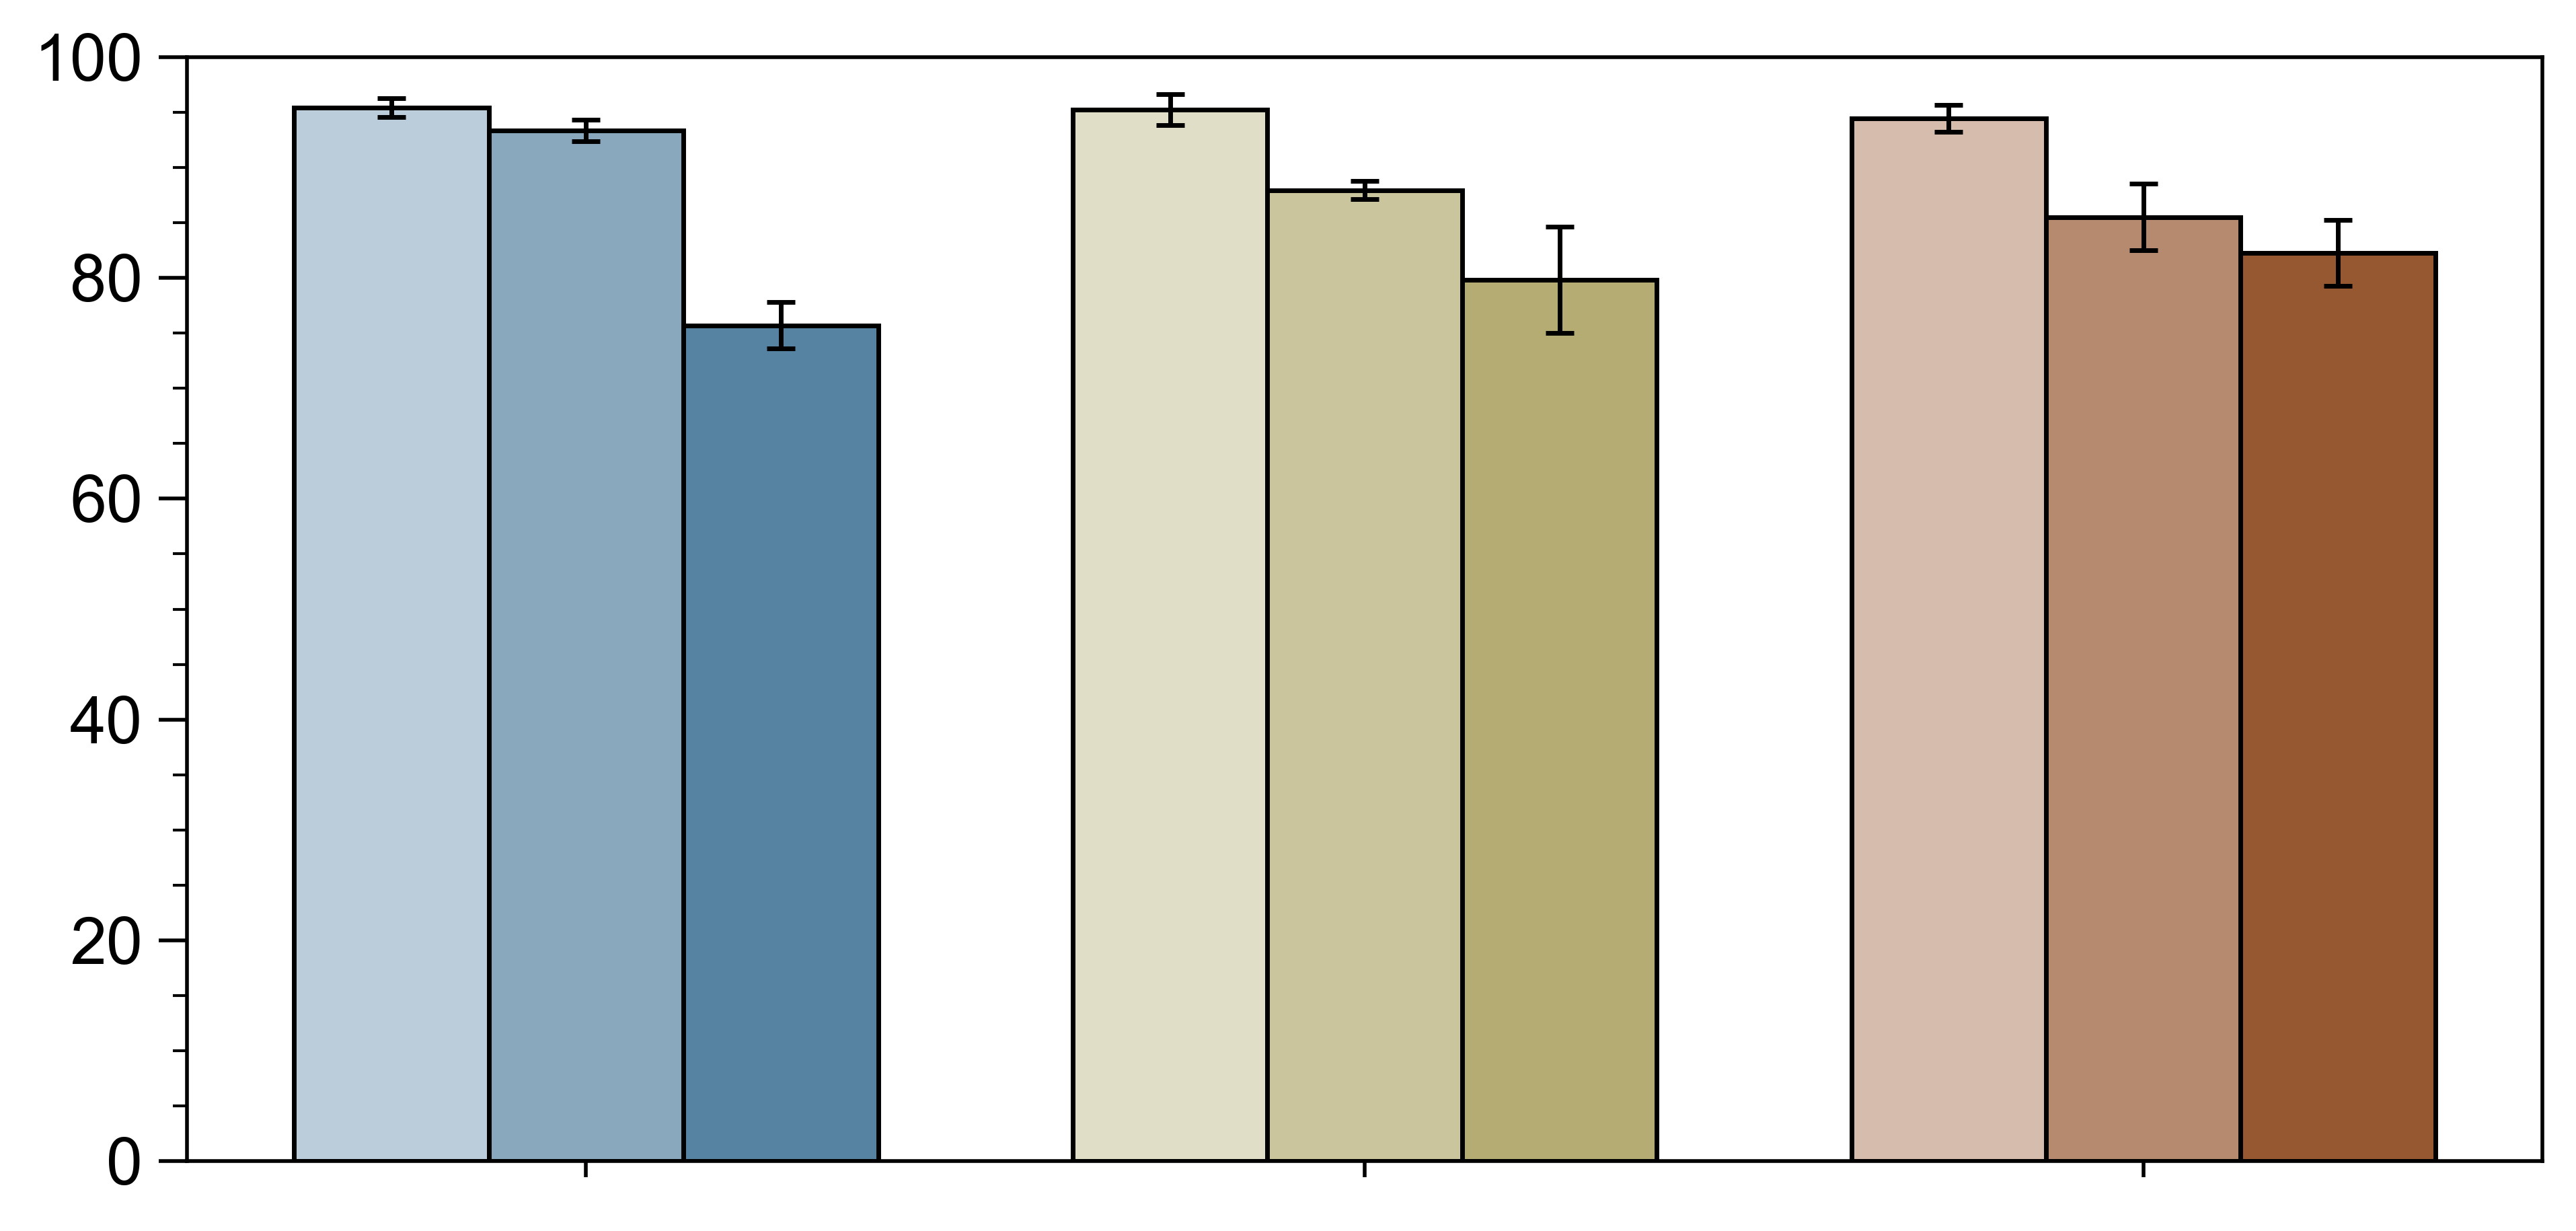

In [4]:
plt.rcParams["font.family"] = "Arial"

ADS_COLOR = {
    "NH2":  "#5683A2",
    "O":    "#965831",
    "NO2":  "#b4ac73",
}

def parse_E(fname):
    stem = os.path.basename(fname)
    stem = os.path.splitext(stem)[0]      # strip .csv regardless of underscore presence
    stem = stem.split("_")[0]              # still handle any trailing _suffix if present
    stem = stem.replace(",", ".")
    if stem.startswith("n"):
        stem = "-" + stem[1:]
    return float(stem)


def lighten(hex_color, factor):
    # factor in [0,1]; 0 = white, 1 = full color
    r, g, b = mcolors.to_rgb(hex_color)
    return (1 - factor * (1 - r), 1 - factor * (1 - g), 1 - factor * (1 - b))


RELAXATION_DIR = "./data/per_ads_10k/energy_data/"

def glob_sorted_by_E(d):
    paths = glob.glob(os.path.join(d, "*.csv"))
    return sorted(paths, key=parse_E)

adsorbate_dirs = {
    d: os.path.join(RELAXATION_DIR, d)
    for d in sorted(os.listdir(RELAXATION_DIR))
    if os.path.isdir(os.path.join(RELAXATION_DIR, d)) and d != "old"
}

files = {ads: glob_sorted_by_E(d) for ads, d in adsorbate_dirs.items()}
for ads, paths in files.items():
    assert len(paths) == 3, f"{ads}: expected 3 files, found {len(paths)}: {paths}"
    print(ads, [os.path.basename(p) for p in paths])

validity_cols = ["vol_ok", "cat_dist_ok", "cat_atom_types_ok", "cat_ads_dist_ok", "ads_dist_ok"]

def validity_score(csv_path):
    df = pd.read_csv(csv_path)
    return 100 * df[validity_cols].all(axis=1).mean()

uniqueness_scores = {
    "NH2": [x * 100 for x in [0.7424, 0.7418, 0.7870]],  # matches -2.09, -0.97, 0.15 order above
    "NO2": [x * 100 for x in [0.8170, 0.8454, 0.7324]],  # matches -0.76, 1.69, 4.14 order above
    "O":   [x * 100 for x in [0.8637, 0.8111, 0.7929]],  # matches -1.76, -0.07, 1.62 order above
}

"""
uniqueness_b = {
    "NH2": [0.8591, 0.8507, 0.8461],
    "NO2": [0.87,   0.89,   0.8222],
    "O":   [0.771,  0.7733, 0.7757],
}

uniqueness_scores = {
    ads: [x * y  for x, y in zip(uniqueness_a[ads], uniqueness_b[ads])]
    for ads in uniqueness_a
}
"""

novelty_scores = {
    "NH2": [x * 100 for x in [0.9335, 0.9213, 0.9455]],
    "NO2": [x * 100 for x in [0.8831, 0.88747, 0.8680]],
    "O":   [x * 100 for x in [0.8733, 0.8129, 0.8795]],
}

results = {}
for ads, paths in files.items():
    val  = np.array([validity_score(p) for p in paths])
    uniq = np.array(uniqueness_scores[ads])
    nov  = np.array(novelty_scores[ads])
    results[ads] = {
        "validity": (val.mean(), val.std()),
        "uniqueness": (uniq.mean(), uniq.std()),
        "novelty": (nov.mean(), nov.std()),
    }

adsorbates = list(results.keys())
x = np.arange(len(adsorbates))
width = 0.25

validity_mean, validity_err     = zip(*(results[a]["validity"] for a in adsorbates))
uniqueness_mean, uniqueness_err = zip(*(results[a]["uniqueness"] for a in adsorbates))
novelty_mean, novelty_err       = zip(*(results[a]["novelty"] for a in adsorbates))

fig, ax1 = plt.subplots(figsize=(8, 4), dpi=500)

# shade order: validity lightest -> novelty -> uniqueness darkest
shades = {"validity": 0.4, "novelty": 0.7, "uniqueness": 1.0}

for i, ads in enumerate(adsorbates):
    base = ADS_COLOR[ads]
    val_mean, val_err = results[ads]["validity"]
    nov_mean, nov_err = results[ads]["novelty"]
    uniq_mean, uniq_err = results[ads]["uniqueness"]

    ax1.bar(i - width, val_mean, width, yerr=val_err, capsize=3,
            error_kw=dict(elinewidth=1, capthick=1),
            color=lighten(base, shades["validity"]), edgecolor="black",
            label="Validity" if i == 0 else None)
    ax1.bar(i, nov_mean, width, yerr=nov_err, capsize=3,
            error_kw=dict(elinewidth=1, capthick=1),
            color=lighten(base, shades["novelty"]), edgecolor="black",
            label="Novelty" if i == 0 else None)
    ax1.bar(i + width, uniq_mean, width, yerr=uniq_err, capsize=3,
            error_kw=dict(elinewidth=1, capthick=1),
            color=lighten(base, shades["uniqueness"]), edgecolor="black",
            label="Uniqueness" if i == 0 else None)

ax1.set_xticks(x)
ax1.set_xticklabels("")
ax1.set_ylim(0, 100)
ax1.tick_params(axis='both', labelsize=14)

ax1.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax1.tick_params(axis='y', which='minor', length=3)
ax1.tick_params(axis='y', which='major', length=6)

plt.tight_layout()
save_flat_svg(fig=fig, path="fig4/panel/val_uniq_novelty.svg")
plt.show()

In [6]:
EMB_KEY = "emb_mean"  # or "emb_max"
OC20_FILENAME = "oc20_embeddings.npz"
DATA_DIR = "/Users/deanmsweeney/Documents/CFM/gace/manuscript/data/per_ads_10k/slab_embeddings_data"
ads_dirs = sorted(d for d in glob.glob(os.path.join(DATA_DIR, "*")) if os.path.isdir(d))

def load_oc20(ads_dir, key=EMB_KEY):
    """Load the OC20 baseline embedding matrix for one adsorbate folder.
    Returns None if oc20_embeddings.npz is not present."""
    path = os.path.join(ads_dir, OC20_FILENAME)
    if not os.path.exists(path):
        return None
    with np.load(path) as d:
        return d[key]


def load_gace(ads_dir, key=EMB_KEY):
    files = sorted(
        f for f in glob.glob(os.path.join(ads_dir, "*.npz"))
        if os.path.basename(f) != OC20_FILENAME
    )
    if not files:
        return None

    mats, sources, labels = [], [], []
    for f in files:
        with np.load(f) as d:
            v = d[key]
        mats.append(v)
        stem = os.path.splitext(os.path.basename(f))[0]  # strip .npz
        sources.extend([stem] * v.shape[0])
        labels.extend([parse_energy(stem)] * v.shape[0])

    vectors = np.concatenate(mats, axis=0)
    return vectors, np.array(sources), np.array(labels)
    
def parse_energy(source):
    s = os.path.basename(source)
    s = s.replace("_embeddings", "")
    s = os.path.splitext(s)[0]  # strips .npz (or any extension) regardless of order
    sign = -1.0 if s.startswith("n") else 1.0
    return sign * float(s.lstrip("n").replace(",", "."))

adsorbate  threshold   novelty  uniqueness
NH2          0.7728    75.94%      20.43%
NO2          0.7118    79.15%      36.52%
O            0.6559    74.68%      41.84%


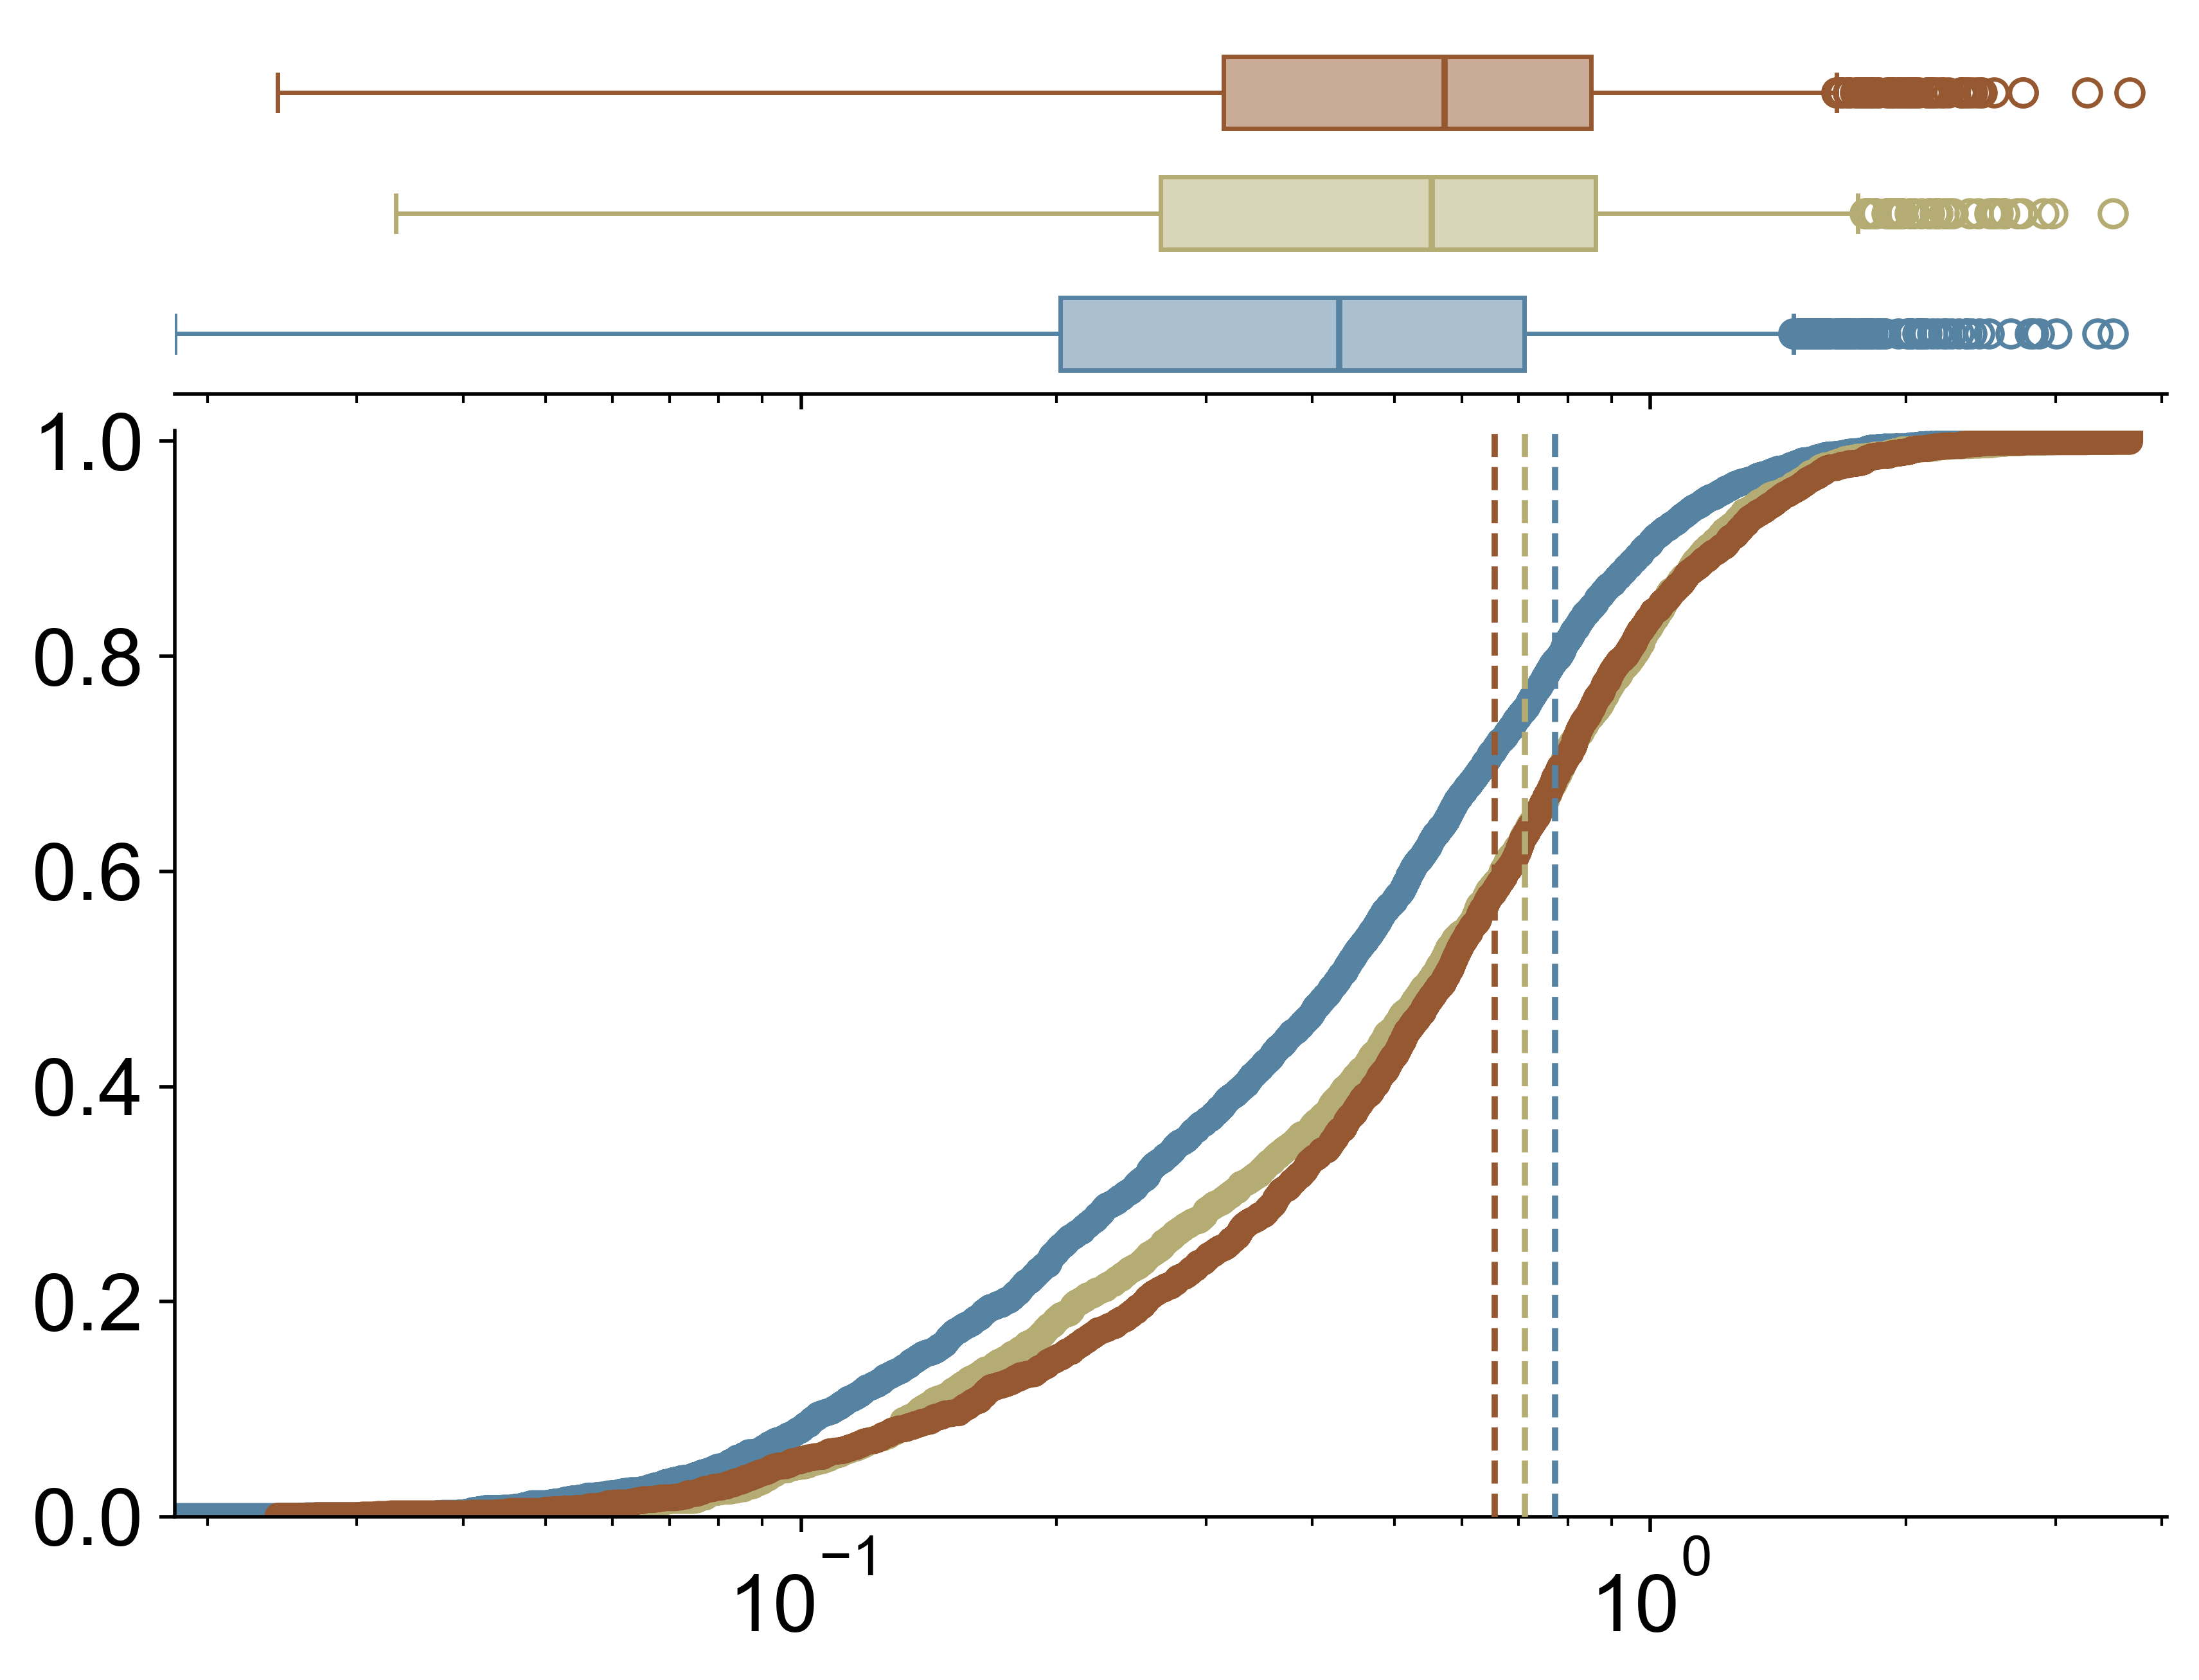

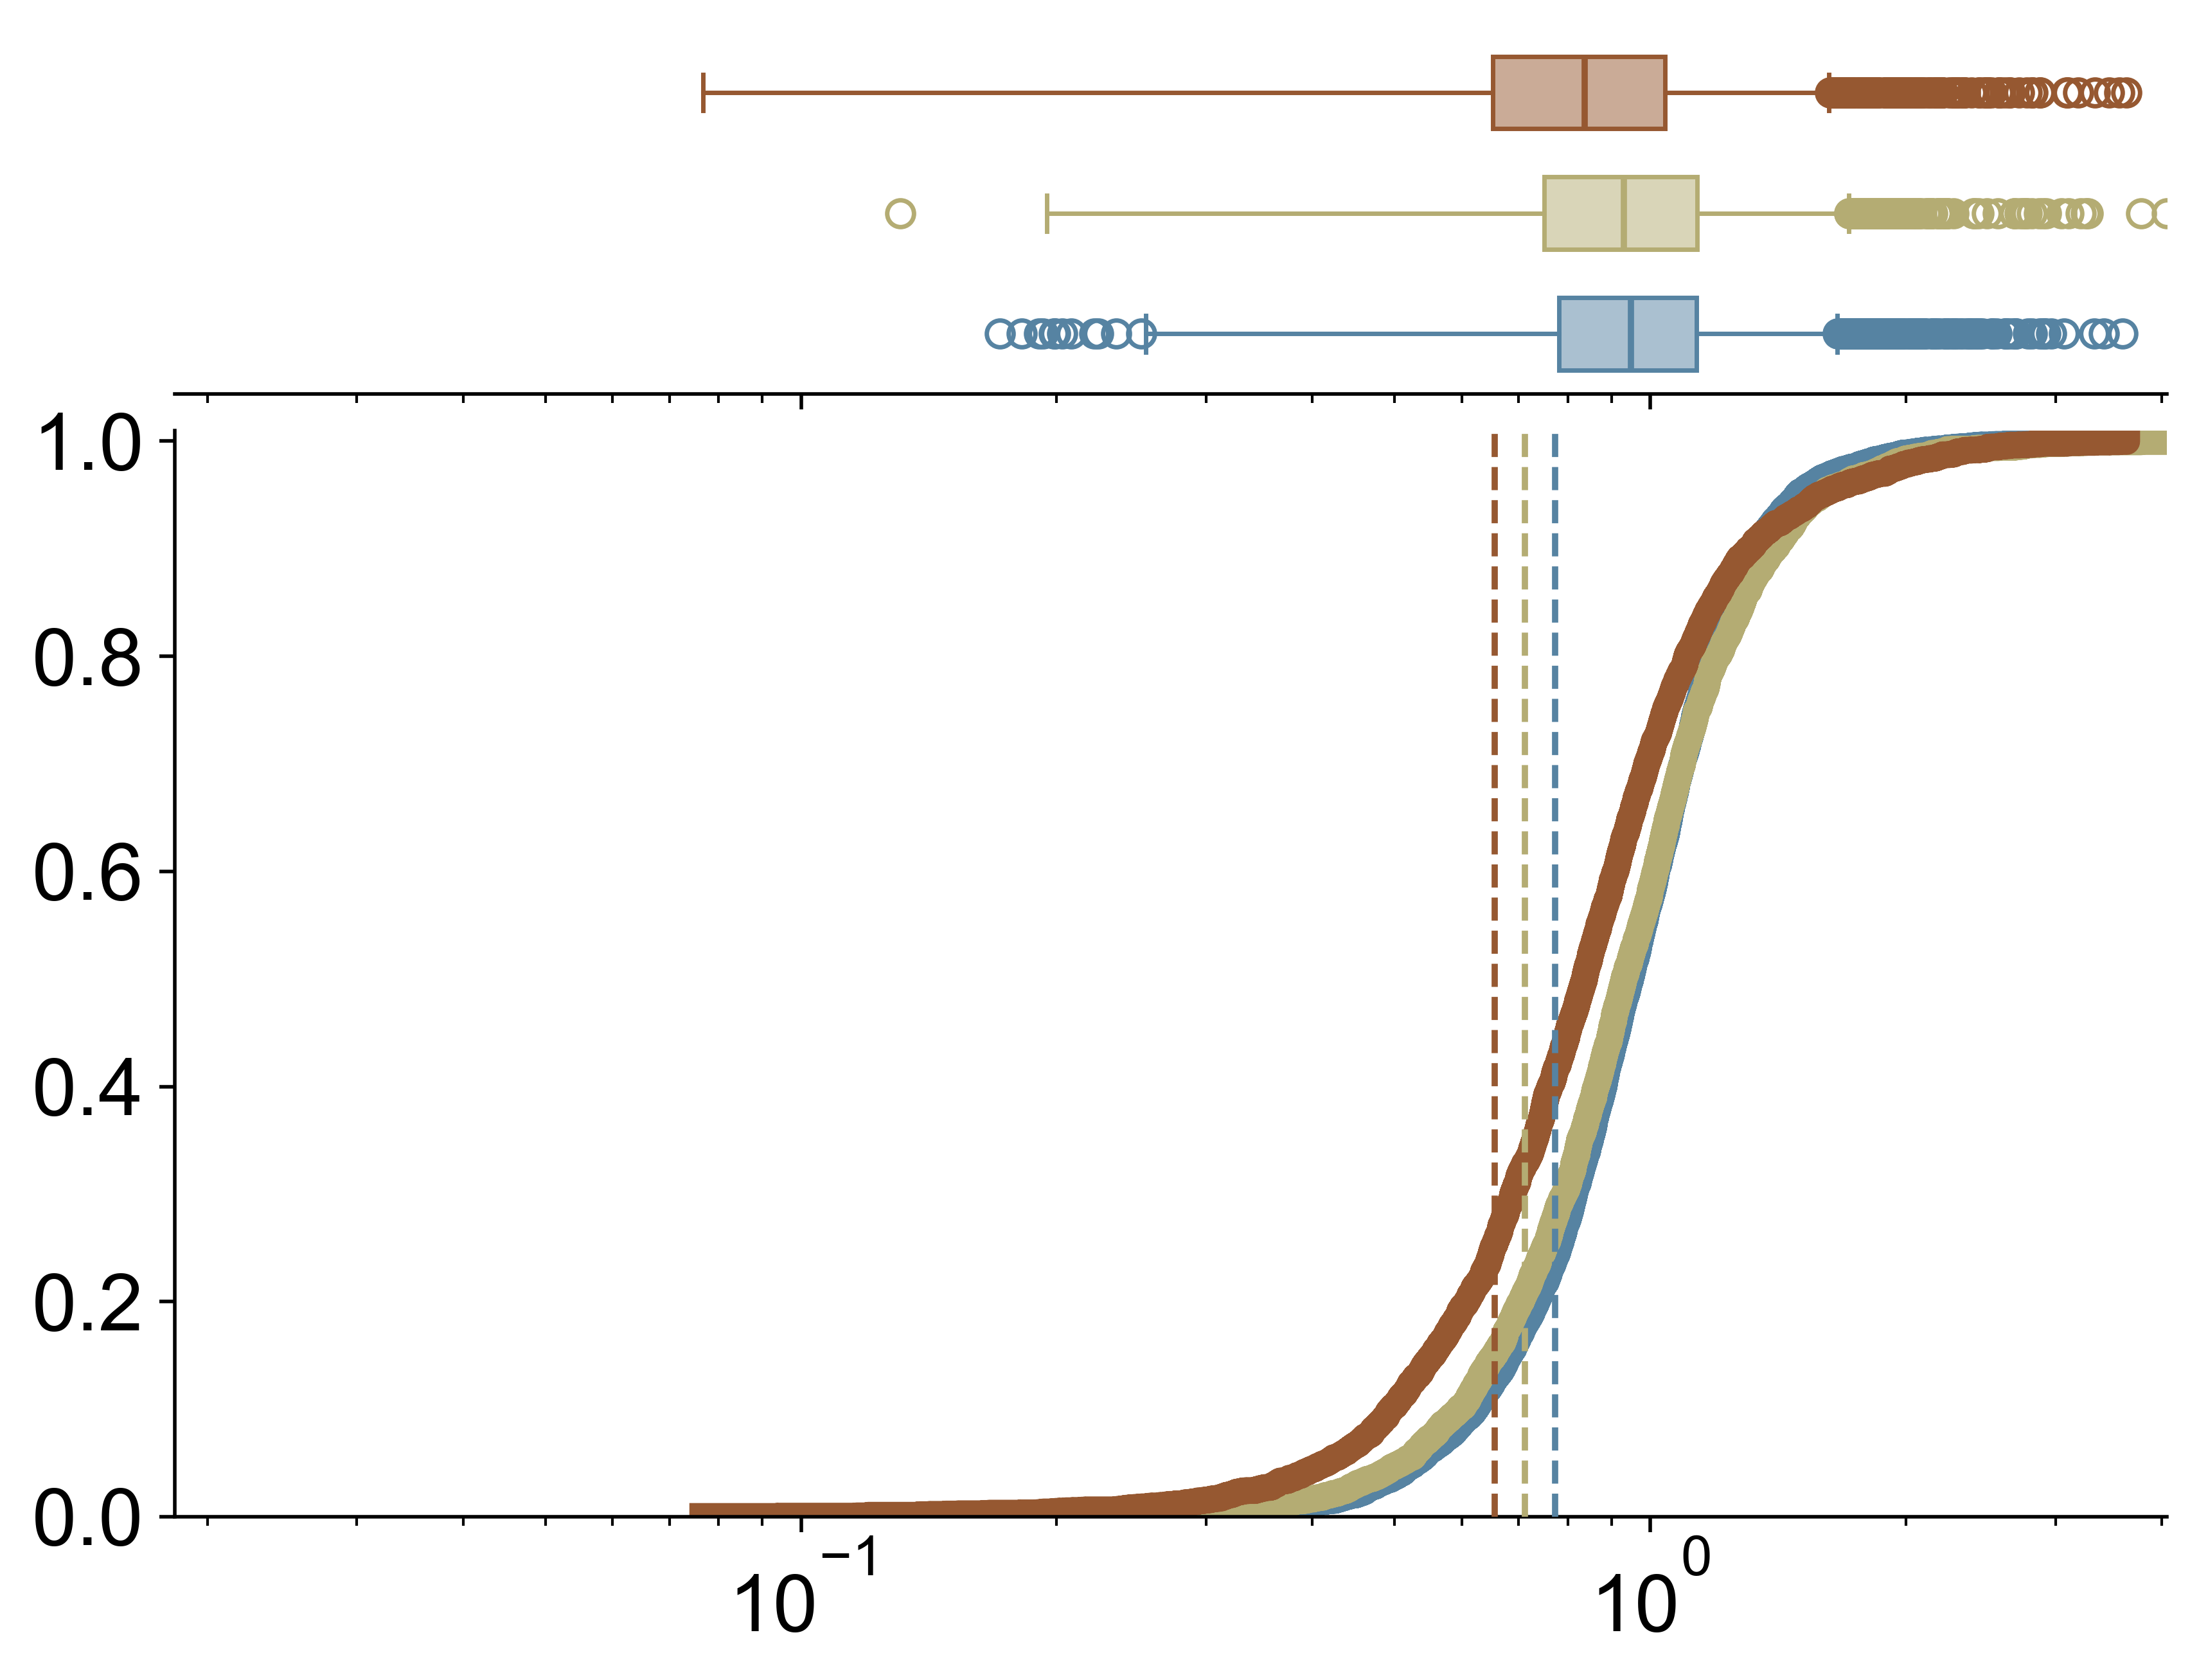

In [7]:
# Assumes `distances`, `COLOR_SCHEME`, and `save_flat_svg` already exist in
# scope from the kNN-violin script this is meant to run alongside.

# One representative color per adsorbate for the pooled plot (COLOR_SCHEME
# has one color per binding-energy target; middle entry used here as the
# default -- swap for a dedicated single-color dict if you'd rather pick
# these by hand).


def knn_dist_to_other(query_vecs, ref_vecs):
    """NN distance from each row in query_vecs to its closest point in ref_vecs."""
    tree = cKDTree(ref_vecs)
    dist, _ = tree.query(query_vecs, k=1)
    return dist


def knn_self_dist(query_vecs, all_vecs, k=1):
    """Mean NN distance from each row in query_vecs to its k closest points in
    all_vecs, excluding itself."""
    tree = cKDTree(all_vecs)
    dist, _ = tree.query(query_vecs, k=k + 1)
    return dist[:, 1:].mean(axis=1)


def compute_target_distances(ads_dir, key=EMB_KEY):
    """For one adsorbate folder, return (targets, oc20_self) where targets is
    {target: {"vs_gace": arr, "vs_oc20": arr}} and oc20_self is the median OC20
    within-population NN distance. Returns None if OC20 or GACE data is missing."""
    oc20 = load_oc20(ads_dir, key)
    gace = load_gace(ads_dir, key)
    if oc20 is None or gace is None:
        return None

    vectors, sources, labels = gace
    targets = sorted(set(sources), key=parse_energy)

    out = {}
    for t in targets:
        gace_t = vectors[sources == t]
        out[t] = {
            "vs_gace": knn_self_dist(gace_t, vectors, 1),
            "vs_oc20": knn_dist_to_other(gace_t, oc20),
        }
        oc20_self = knn_self_dist(oc20, oc20, k=1)
    return out, np.median(oc20_self)


distances = {}
oc20_self = {}
oc20_threshold = {}
for ads_dir in ads_dirs:
    ads = os.path.basename(ads_dir)
    d = compute_target_distances(ads_dir)
    if d is not None:
        distances[ads], oc20_self[ads] = d

def ecdf(data):
    x = np.sort(data)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y


def pooled_distances(distances, ads, kind):
    """Pool a distance array across all binding-energy targets for one
    adsorbate. kind: 'vs_oc20' for novelty, 'vs_gace' for uniqueness."""
    target_dists = distances[ads]
    return np.concatenate([target_dists[t][kind] for t in target_dists])


def fraction_above_threshold(data, threshold):
    """Novelty/uniqueness fraction at a distance threshold: proportion of
    points farther than threshold (i.e. no neighbor within it)."""
    return float(np.mean(data > threshold))


def novelty_uniqueness_table(distances, oc20_self, ads_list=None):
    """Per-adsorbate novelty and uniqueness fraction at that adsorbate's own
    OC20 self-distance threshold (D50, from oc20_self dict)."""
    if ads_list is None:
        ads_list = sorted(distances.keys())

    rows = {}
    for ads in ads_list:
        threshold = oc20_self[ads]
        rows[ads] = {
            "threshold": threshold,
            "novelty": fraction_above_threshold(pooled_distances(distances, ads, "vs_oc20"), threshold),
            "uniqueness": fraction_above_threshold(pooled_distances(distances, ads, "vs_gace"), threshold),
        }

    print(f"{'adsorbate':<8} {'threshold':>10} {'novelty':>9} {'uniqueness':>11}")
    for ads, r in rows.items():
        print(f"{ads:<8} {r['threshold']:>10.4f} {r['novelty']:>9.2%} {r['uniqueness']:>11.2%}")

    return rows


def box_cdf_plot(ax_box, ax_cdf, ads_list, distances, kind, colors, oc20_self=None):
    for i, ads in enumerate(ads_list):
        data = pooled_distances(distances, ads, kind)
        color = colors[ads]

        ax_box.boxplot(
            data,
            vert=False,
            positions=[i],
            widths=0.6,
            patch_artist=True,
            boxprops=dict(facecolor=to_rgba(color, 0.5), edgecolor=color, linewidth=1.0),
            medianprops=dict(color=color, linewidth=1.4),
            whiskerprops=dict(color=color, linewidth=1.0),
            capprops=dict(color=color, linewidth=1.0),
            flierprops=dict(marker="o", markersize=6, markeredgecolor=color, markerfacecolor="none"),
        )

        x, y = ecdf(data)
        label = ads
        if oc20_self is not None:
            threshold = oc20_self[ads]
            frac = fraction_above_threshold(data, threshold)
            label = f"{ads} ({frac:.0%} @ D50)"
            ax_cdf.axvline(threshold, color=color, linestyle="--", linewidth=1.4, zorder=5)

        ax_cdf.plot(x, y, drawstyle="steps-post", color=color, linewidth=6, label=label)

    ax_box.set_yticks([])
    ax_box.spines[["top", "right", "left"]].set_visible(False)

    ax_cdf.set_xscale("log")
    ax_cdf.set_ylim(0, 1.01)
    ax_cdf.spines[["top", "right"]].set_visible(False)
    #ax_cdf.legend(frameon=False, fontsize=8)


def make_novelty_uniqueness_cdfs(distances, oc20_self, ads_list=None, colors=ADS_COLOR):
    if ads_list is None:
        ads_list = sorted(distances.keys())

    kinds = [
        ("vs_gace", "NN distance to other GACE samples", "uniqueness_cdf.svg"),
        ("vs_oc20", "NN distance to OC20", "novelty_cdf.svg"),
    ]

    # shared x-limits across both plots, based on pooled data from both kinds
    all_data = np.concatenate([
        pooled_distances(distances, ads, kind)
        for kind, _, _ in kinds
        for ads in ads_list
    ])
    xlim = (all_data.min(), all_data.max())

    for kind, xlabel, fname in kinds:
        fig, (ax_box, ax_cdf) = plt.subplots(
            2, 1, figsize=(8, 6), dpi=500,
            gridspec_kw={"height_ratios": [1, 3], "hspace": 0.05},
            sharex=True,
        )
        box_cdf_plot(ax_box, ax_cdf, ads_list, distances, kind, colors, oc20_self=oc20_self)
        ax_cdf.set_xlim(xlim)
        save_flat_svg(fig=fig, path=f"./fig4/panel/{fname}")


novelty_uniqueness_table(distances, oc20_self)
make_novelty_uniqueness_cdfs(distances, oc20_self)

In [8]:
import random

def load_gace_paths(ads_dir):
    """Load every CSV of {path, natoms} in ads_dir and concatenate into one
    array of paths, tracking which source file (conditioning target) each
    row came from -- same sorted-filename order and same source-tracking
    convention as load_gace (CSV and npz share the same stem, so row i here
    matches row i in `vectors`/`sources`)."""
    csv_paths = sorted(glob.glob(os.path.join(ads_dir, "*.csv")))

    paths, sources = [], []
    for f in csv_paths:
        source = os.path.splitext(os.path.basename(f))[0]
        df = pd.read_csv(f)
        paths.append(df["path"].values)
        sources += [source] * len(df)

    paths = np.concatenate(paths, axis=0)
    sources = np.array(sources)
    return paths, sources


TOP_FRAC = 0.10
N_SAMPLE = 3
SEED = 0
rng = random.Random(SEED)

ads_dirs = sorted(d for d in glob.glob(os.path.join("/Users/deanmsweeney/Documents/CFM/gace/manuscript/data/per_ads_10k/slab_embeddings_data", "*")) if os.path.isdir(d))
for ads_dir in ads_dirs:
    ads_name = os.path.basename(ads_dir)

    oc20 = load_oc20(ads_dir)
    gace = load_gace(ads_dir)
    if oc20 is None or gace is None:
        print(f"Skipping {ads_name}: missing OC20 or GACE data.")
        continue
    vectors, sources, labels = gace

    novelty = knn_dist_to_other(vectors, oc20)  # per-row NN distance to OC20

    paths, path_sources = load_gace_paths(ads_dir)
    assert np.array_equal(sources, path_sources), f"{ads_name}: CSV/npz row order mismatch!"

    n_top = max(1, int(np.ceil(TOP_FRAC * len(novelty))))
    top_idx = np.argsort(novelty)[::-1][:n_top]  # most novel first

    sample_idx = rng.sample(list(top_idx), k=min(N_SAMPLE, len(top_idx)))

    print(f"=== {ads_name} ===  (top {TOP_FRAC:.0%} = {n_top} structures)")
    for i in sample_idx:
        print(f"  path={paths[i]}  source={sources[i]}  E={labels[i]:.2f}  novelty={novelty[i]:.4f}")

=== NH2 ===  (top 10% = 610 structures)
  path=3_threshold/1_431.traj  source=n0,97_embeddings  E=-0.97  novelty=1.4307
  path=1_threshold/0_24.traj  source=n0,97_embeddings  E=-0.97  novelty=1.4127
  path=2_threshold/8_343.traj  source=0,15_embeddings  E=0.15  novelty=2.2262
=== NO2 ===  (top 10% = 313 structures)
  path=3_threshold/5_198.traj  source=4,14_embeddings  E=4.14  novelty=1.6603
  path=2_threshold/4_306.traj  source=1,69_embeddings  E=1.69  novelty=1.4482
  path=3_threshold/0_734.traj  source=4,14_embeddings  E=4.14  novelty=1.4669
=== O ===  (top 10% = 358 structures)
  path=2_threshold/3_0.traj  source=1,62_embeddings  E=1.62  novelty=1.5354
  path=1_threshold/6_510.traj  source=1,62_embeddings  E=1.62  novelty=1.6558
  path=3_threshold/4_171.traj  source=1,62_embeddings  E=1.62  novelty=1.4656
